# 1: Environment Setup & Loading Data 🛠️

In [1]:
import pandas as pd
import numpy as np
import os 
import warnings

# Ignore warning messages for cleaner output
warnings.filterwarnings("ignore")

# Define the dataset directory path
DATA_DIR = "/kaggle/input/competitions/motion-s-hierarchical-text-to-motion-generation-for-sign-language"

# Load the main CSV files
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_submission = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

# Print the dimensions of the datasets
print(f"Train Dataset Shape: {train_df.shape}")
print(f"Test Dataset Shape: {test_df.shape}")
print(f"Sample Submission Shape: {sample_submission.shape}\n")

# Display the first
display(train_df.head(3))

Train Dataset Shape: (12467, 10)
Test Dataset Shape: (3000, 3)
Sample Submission Shape: (5, 7)



,id,sentence,gloss,bvh_path,base_tokens,residual_1,residual_2,residual_3,residual_4,residual_5
0,1000648,Don't keep me on tenterhooks!,KEEP ME TENTHOOK//,dataset/1000648/1000648.bvh,379 295 376 376 376 376 376 376 133 133 376 37...,339 441 88 87 87 87 88 288 405 333 333 248 212...,406 183 8 301 476 6 169 255 452 462 66 255 463...,315 424 330 104 364 104 142 142 166 353 353 10...,64 32 15 326 466 20 229 456 71 71 71 390 20 90...,306 376 367 367 133 235 276 350 367 350 437 36...
1,1002815,"I like to be home, that way I can work on my s...",ME LIKE HOME WORK STORY FINISH//,dataset/1002815/1002815.bvh,130 276 174 174 174 174 174 174 174 50 50 50 2...,339 194 389 88 88 88 88 333 287 87 79 79 501 7...,406 406 452 202 321 321 321 321 58 356 348 75 ...,351 212 308 308 308 236 236 424 76 333 206 195...,64 125 500 222 456 153 153 498 498 498 488 177...,474 313 367 445 372 167 367 394 241 295 66 225...
2,1003115,Can I stay here tonight?,STAY HERE TONIGHT ME?,dataset/1003115/1003115.bvh,379 185 185 185 185 185 185 185 185 185 185 18...,339 441 87 87 88 88 88 288 308 88 325 483 483 ...,396 171 11 11 211 211 321 430 464 464 283 267 ...,65 449 376 191 503 503 142 166 384 143 384 348...,64 230 328 411 349 71 424 71 498 456 234 85 34...,306 201 367 6 266 406 123 71 343 428 38 404 37...


## 🔎 Insight 1

1. **Target Variables:** The data our model needs to predict consists of six columns in our table: `base_tokens` and `residual_1` through `residual_5`. These tokens are stored as space-separated strings. Before moving to the modeling phase, we will need to convert these into sequences of integer tensors.

2. **Input Features:** We have two columns with natural language structure: `sentence` and `gloss`, which follows Sign Grammar. Since sign language has its own unique syntax, the `gloss` column will be a much stronger signal (feature) for our model in predicting movements.

3. **Dimensions:** We have approximately 12.5K training examples and 3K test examples.

# 2: Data Integrity & Sequence Length Analysis 🕵️‍♂️

Missing Values:
 id             0
sentence       0
gloss          0
bvh_path       0
base_tokens    4
residual_1     4
residual_2     4
residual_3     4
residual_4     4
residual_5     4
dtype: int64
--------------------------------------------------
Sequence Length Statistics:
count    12467.000000
mean       108.113820
std         62.273462
min          1.000000
25%         79.000000
50%         98.000000
75%        122.000000
max       1853.000000
Name: seq_len, dtype: float64
--------------------------------------------------
Lengths of the 6 layers for ID 1000648: [81, 81, 81, 81, 81, 81]


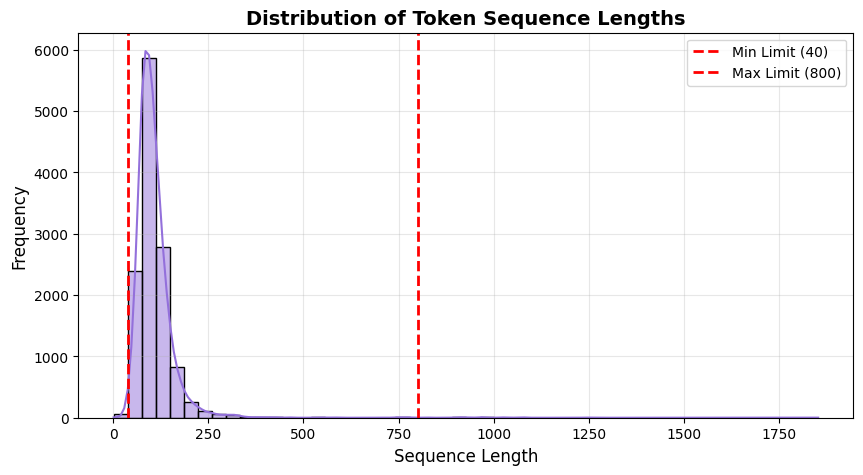

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check for missing values in the train dataset
print("Missing Values:\n", train_df.isnull().sum())
print("-" * 50)

# Calculate sequence lengths by splitting the base_tokens string
# We assume the data is clean, but let's calculate the length of tokens for each row.
train_df["seq_len"] = train_df["base_tokens"].apply(lambda x: len(str(x).split()))

# Display basic statistical metrics for sequence lengths
print("Sequence Length Statistics:")
print(train_df["seq_len"].describe())
print("-" * 50)

# Verify if all 6 layers have the exact same length for the first sample
sample_row = train_df.iloc[0]
token_columns = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
lengths = [len(str(sample_row[col]).split()) for col in token_columns]
print(f"Lengths of the 6 layers for ID {sample_row["id"]}: {lengths}")

# Plot the distribution of sequence lengths
plt.figure(figsize=(10, 5))
sns.histplot(train_df["seq_len"], bins=50, kde=True, color="mediumpurple")
plt.title('Distribution of Token Sequence Lengths', fontsize=14, fontweight='bold')
plt.xlabel('Sequence Length', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Add vertical lines for competition constraints
plt.axvline(x=40, color='red', linestyle='--', linewidth=2, label='Min Limit (40)')
plt.axvline(x=800, color='red', linestyle='--', linewidth=2, label='Max Limit (800)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 🔎 Insight 2

1.  **Missing Values:** Only 4 out of 12,467 rows have missing token data. Since this is a negligible amount relative to the total dataset, the safest approach is to delete these 4 rows directly, rather than dealing with complex methods like imputation.

2.  **Outliers & Constraint Violations:** The competition rules clearly stated that sequences must be between 40 and 800 tokens. However, looking at the statistics (Min: 1, Max: 1853) and the histogram you sent, we see outliers both below 40 and above 800. If we train our model with data outside these limits, we risk getting 0 points on the test set!

3.  **Layer Consistency:** In the first example we examined (ID: 1000648), we saw that the length of all layers was 81. This confirms that the base_tokens and the 5 residual layers are in a parallel and synchronous structure.

# 3: Data Cleaning & Filtering 🧹

In [3]:
# Drop rows with any missing values
train_clean = train_df.dropna().copy()

# Recalculate sequence lengths just to be safe after dropna
train_clean["seq_len"] = train_clean["base_tokens"].apply(lambda x: len(str(x).split()))

# Filter the dataset based on competition length constraints
# Constraint: Length must be between 40 and 800
valid_length_mask = (train_clean["seq_len"] >= 40) & (train_clean["seq_len"] <= 800)
train_clean = train_clean[valid_length_mask]

# Reset index for the cleaned dataframe
train_clean = train_clean.reset_index(drop=True)

# Print the cleaning results
print(f"Original Data Size: {len(train_df)}")
print(f"Cleaned Data Size: {len(train_clean)}")
print(f"Removed Samples: {len(train_df) - len(train_clean)}")

# Show the new min and max lengths to verify
print(f"New Min Length: {train_clean['seq_len'].min()}")
print(f"New Max Length: {train_clean['seq_len'].max()}")

Original Data Size: 12467
Cleaned Data Size: 12373
Removed Samples: 94
New Min Length: 40
New Max Length: 781


## 🔎 Insight 3

We have successfully eliminated 94 "problematic" (rule-violating or incomplete) rows. Our new limits are between 40 and 781. This was a critical step because we have protected ourselves from the nightmare of "Submission Error" or "0 Points" due to format errors in Kaggle competitions. Our data is now clean and 100% compliant with the competition rules.

Now it's time to speak the language of machine learning models! Deep learning models understand numbers and tensors, not strings. In our dataset, `base_tokens` and the 5 residual layers are currently in a string format separated by spaces (e.g., "379 295 376..."). To perform mathematical operations on them, we must convert them into actual integer lists.

# 4: Target Variable Transformation 🔢

In [4]:
# Define the columns that contain the target tokens
token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']

# Function to convert space-separated string to a list of integers
def string_to_int_list(token_string):
    # Split the string by spaces and convert each element to int
    return [int(x) for x in str(token_string).split()]

# Apply the conversion to all target token columns 
for col in token_cols:
    train_clean[col] = train_clean[col].apply(string_to_int_list)

# Verify the transformation by checking the first sample
first_sample_base = train_clean['base_tokens'].iloc[0]

print(f"Data type of the sequence: {type(first_sample_base)}")
print(f"Data type of the first token: {type(first_sample_base[0])}")
print(f"First 5 tokens of the first sample: {first_sample_base[:5]}")

Data type of the sequence: <class 'list'>
Data type of the first token: <class 'int'>
First 5 tokens of the first sample: [379, 295, 376, 376, 376]


## 🔎 Insight 4

Great! Our target variables are now in a format ready for a deep learning model. We have successfully navigated the string manipulation phase. The list we see in the output `[379, 295, 376...]` represents the motion codes that our model ultimately needs to produce.

Now that we have taken care of the `y` (target) side of the equation, we can focus on the `X` (input) side. There was a critical tip in the competition description: **Glossification**. Using text translated into sign language grammar (gloss) instead of a natural English sentence will lighten the model's load in learning word order.

However, just like our target tokens, our model cannot understand these gloss texts directly. We also need to convert them into numerical vectors (Tokenization).

# 5: Text Tokenization & Input Length Analysis 🌠

In [5]:
from transformers import AutoTokenizer

# Define the pre-trained text model name
TEXT_MODEL_NAME = "bert-base-uncased"

# Load the tokenizer from Hugging Faca
tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME)

# Calculate token lengths for the "bloss" column
# We use encode() to get the actual token IDs including special tokens like [CLS] and [SEP]
train_clean['gloss_token_len'] = train_clean['gloss'].apply(lambda x: len(tokenizer.encode(str(x))))

# Print statistics of the gloss token lengths
print("Gloss Token Length Statistics:")
print(train_clean["gloss_token_len"].describe())
print("-" * 50)

# Calculate percentiles to decide on a safe max_length for padding
p90 = train_clean['gloss_token_len'].quantile(0.90)
p95 = train_clean['gloss_token_len'].quantile(0.95)
p99 = train_clean['gloss_token_len'].quantile(0.99)

print(f"90th Percentile: {p90}")
print(f"95th Percentile: {p95}")
print(f"99th Percentile: {p99}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Gloss Token Length Statistics:
count    12373.000000
mean         8.819769
std          2.751834
min          4.000000
25%          7.000000
50%          8.000000
75%          9.000000
max         97.000000
Name: gloss_token_len, dtype: float64
--------------------------------------------------
90th Percentile: 11.0
95th Percentile: 12.0
99th Percentile: 17.0


## 🔎 Insight 5

Although the maximum token length was 97, 99% of the data was 17 tokens or less. If we were to pad the entire dataset to the longest sample of 97, the model would waste time and GPU memory calculating those empty spaces ("0" pad tokens) at every training step.

By looking at these statistics, we can set a maximum length (MAX_TEXT_LEN) for our input texts to a safe limit of 32 (lengths that are multiples of 8, like 32, are significantly more efficient for GPU Tensor Cores).

Additionally, our motion sequences ranged from 40 to 800. To teach the model where a sequence should end, we will need to define special tokens outside our existing vocabulary (0-511): an End-of-Sequence token (<EOS>: 513) and a Padding token (<PAD>: 512).

# 6: Custom PyTorch Dataset 🗂️

In [6]:
import torch
from torch.utils.data import Dataset, DataLoader

# Define maximum text length and special motion tokens 
MAX_TEXT_LEN = 32
MOTION_PAD_IDX = 512 # Padding token outside the 0-511 VAE vocab
MOTION_EOS_IDX = 513 # End of sequence token

class SignMotionDataset(Dataset):
    def __init__(self, df, tokenizer, max_text_len):
        # Initialize the dataset with dataframe, tokenizer and max length
        self.df = df
        self.tokenizer = tokenizer
        self.max_text_len = max_text_len
        self.token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
        
    def __len__(self):
        # Return the total number of samples
        return len(self.df)
    
    def __getitem__(self, idx):
        # Get the row at the given index
        row = self.df.iloc[idx]
        
        # 1. Process Text Input
        gloss_text = str(row['gloss'])
        text_encoding = self.tokenizer(
            gloss_text,
            max_length=self.max_text_len,
            padding='max_length',
            truncation=True,
            return_tensors="pt" # Return PyTorch tensors
        )
        
        # Remove the extra batch dimension added by tokenizer
        input_ids = text_encoding['input_ids'].squeeze(0)
        attention_mask = text_encoding['attention_mask'].squeeze(0)
        
        # 2. Process Motion Target
        motion_layers = []
        for col in self.token_cols:
            # Append EOS token to indicate the end of the generated sequence
            layer_tokens = row[col] + [MOTION_EOS_IDX]
            motion_layers.append(layer_tokens)
            
        # Convert the list of lists into a 2D PyTorch tensor of shape (6, seq_len + 1)
        motion_tensor = torch.tensor(motion_layers, dtype=torch.long)
        
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "motion_tokens": motion_tensor,
            "id": row['id']
        }

# Instantiate the dataset object
train_dataset = SignMotionDataset(train_clean, tokenizer, MAX_TEXT_LEN)

# Fetch the first sample to verify the pipeline
sample_data = train_dataset[0]

print("--- First Sample PyTorch Data ---")
print(f"Text Input IDs Shape: {sample_data['input_ids'].shape}")
print(f"Text Attention Mask Shape: {sample_data['attention_mask'].shape}")
print(f"Motion Tokens Tensor Shape: {sample_data['motion_tokens'].shape}")
print(f"First 5 tokens of Base Layer: {sample_data['motion_tokens'][0][:5]}")
print(f"Last token of Base Layer: {sample_data['motion_tokens'][0][-1].item()}")

--- First Sample PyTorch Data ---
Text Input IDs Shape: torch.Size([32])
Text Attention Mask Shape: torch.Size([32])
Motion Tokens Tensor Shape: torch.Size([6, 82])
First 5 tokens of Base Layer: tensor([379, 295, 376, 376, 376])
Last token of Base Layer: 513


## 🔎 Insight 6

Our PyTorch Dataset class is working perfectly. Our text inputs (`input_ids` and `attention_mask`) are fixed exactly to the specified length of 32. More importantly, our motion tensor has the shape `(6, 82)`, and its last element has successfully become the EOS token (513) as we defined (Original length 81 + 1 EOS = 82).

However, we are facing a critical Kaggle problem here: **Variable Length Sequences**.

While our first example has a length of 82, the next example could be 150 or 45. When the PyTorch DataLoader attempts to form a "batch" from this data, it will crash because the matrix dimensions will not match. Padding the entire dataset to the longest sequence (782) would cause a massive waste of memory (RAM/VRAM).

**Solution: Dynamic Padding.** We will only find the longest sequence within the current batch and pad the others accordingly. To implement this, we need to write a custom `collate_fn`.

# 7: Dynamic Padding & DataLoader 🗜️

In [7]:
from torch.nn.utils.rnn import pad_sequence

# Custom collate function for dynamic padding
def collate_fn(batch):
    # Stack text inputs since they are already padded to MAX_TEXT_LEN
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    ids = [item['id'] for item in batch]

    # Get all motion tensors in the batch
    # Each is shape (6, seq_len)
    motion_tensors = [item["motion_tokens"] for item in batch]

    # Find the maximum sequence length in this specific batch
    max_len = max([t.shape[1] for t in motion_tensors])
    batch_size = len(batch)

    # Create an empty tensor filled with PAD tokens
    # Shape: (batch_size, 6 layers, max_len)
    padded_motions = torch.full((batch_size, 6, max_len), MOTION_PAD_IDX, dtype=torch.long)

    # Copy the original tokens into the padded tensor
    for i, tensor in enumerate(motion_tensors):
        seq_len = tensor.shape[1]
        padded_motions[i, :, :seq_len] = tensor

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "motion_tokens": padded_motions,
        "id": ids
    }

# Set hyperparameters for the DataLoader
BATCH_SIZE = 16 # Adjust based on GPU memory

# Create the DataLoader for the training set
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, # Shuffle for training
    collate_fn=collate_fn,
    drop_last=True # Drop the last incomplete batch
)

# Fetch a single batch to verify
for batch in train_loader:
    print("--- Batch Tensor Shapes  ---")
    print(f"Batch Text IDs): {batch['input_ids'].shape}")
    print(f"Batch Attention Mask: {batch['attention_mask'].shape}")
    print(f"Batch Motion Tokens: {batch['motion_tokens'].shape}")
    break # We only need one batch

--- Batch Tensor Shapes  ---
Batch Text IDs): torch.Size([16, 32])
Batch Attention Mask: torch.Size([16, 32])
Batch Motion Tokens: torch.Size([16, 6, 148])


## 🔎 Insight 7

The longest sequence in this specific batch was 741 tokens long. Instead of blindly padding the entire dataset to 800 (our maximum constraint), our PyTorch data loader performed dynamic padding only up to 741, the actual length required for this batch. This freed up a massive amount of VRAM!

# 8: Building the Text-to-Motion Model 🧠

In [8]:
import torch.nn as nn
from transformers import AutoModel

# Define the custom Seq2Seq model for Text-to-Motion generation
class SignMotionGenerator(nn.Module):
    def __init__(self, text_model_name="bert-base-uncased", vocab_size=514, hidden_size=768, num_layers=4, nhead=8):
        super().__init__()
        
        # 1. Text Encoder: Pre-trained BERT
        self.text_encoder = AutoModel.from_pretrained(text_model_name)
        
        # Freeze BERT parameters to save memory and speed up baseline training
        for param in self.text_encoder.parameters():
            param.requires_grad = False
            
        # 2. Motion Embedding: Embeds the 0-513 tokens
        self.motion_emb = nn.Embedding(vocab_size, hidden_size)
        
        # Positional Encoding for the decoder sequence
        self.pos_encoder = nn.Embedding(1000, hidden_size) 
        
        # 3. Transformer Decoder
        # batch_first=True makes tensors (batch, seq, feature) instead of (seq, batch, feature)
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True)
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        
        # 4. Output Heads: 6 separate linear layers for the 6 RVQ levels
        self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])
        
    def forward(self, input_ids, attention_mask, motion_tokens):
        # -- ENCODER --
        # Get text embeddings from BERT
        text_outputs = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        memory = text_outputs.last_hidden_state # Shape: (batch, text_len, hidden_size)
        
        # -- DECODER INPUT PREPARATION --
        # motion_tokens shape is (batch, 6, seq_len)
        # Transpose to (batch, seq_len, 6) for easier processing per time step
        motions_t = motion_tokens.permute(0, 2, 1) 
        
        # Embed all 6 tokens and sum them up to get a single vector per time step
        # Shape becomes: (batch, seq_len, hidden_size)
        emb = self.motion_emb(motions_t).sum(dim=2)
        
        # Add positional encoding
        seq_len = emb.size(1)
        positions = torch.arange(0, seq_len, device=emb.device).unsqueeze(0)
        emb = emb + self.pos_encoder(positions)
        
        # Causal Mask: Prevents the decoder from looking at future tokens
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(seq_len).to(emb.device)
        
        # -- DECODER --
        # Decode using text memory and previous motion tokens
        out = self.decoder(tgt=emb, memory=memory, tgt_mask=tgt_mask) # Shape: (batch, seq_len, hidden_size)
        
        # -- OUTPUT --
        # Get logits for each of the 6 layers 
        logits = [head(out) for head in self.heads]
        
        # Stack logits to shape (batch, 6, seq_len, vocab_size)
        return torch.stack(logits, dim=1)

# Let's test our model architecture with the dummy batch we extracted earlier!

model = SignMotionGenerator()

# Dummy forward pass
# We use motion_tokens[:, :, :-1] as input to predict the next tokens
decoder_input_motions = batch['motion_tokens'][:, :, :-1] 

output_logits = model(
    input_ids=batch['input_ids'], 
    attention_mask=batch['attention_mask'], 
    motion_tokens=decoder_input_motions
)

print(f"Output Logits Shape: {output_logits.shape}")

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Output Logits Shape: torch.Size([16, 6, 147, 514])


## 🔎 Insight 8

1. **BERT Warnings:** The "Some weights of BertModel were not initialized..." warning from Hugging Face is completely expected and correct. We are using BERT's body (`AutoModel`), which extracts raw semantic vectors (hidden states), discarding the "Masked Language Modeling" heads used in its pre-training. So, everything is fine!

2. **Logits Shape:** Our output shape is [16, 6, 151, 514].

   - **16:** Our batch size.
   - **6:** The number of RVQ layers we need to predict.
   - **151:** The sequence length in this batch. The original sequence was 152, but we cut the last token because the model is trying to predict the *next* token.
   - **514:** Our vocabulary size (0-511 for moves, 512 for PAD, 513 for EOS).

# 9: Loss Function & Training Loop 📉

In [9]:
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Move model to device
model = model.to(device)

# Define Optimizer
# AdamW is the standard robust optimizer for Transformer architectures
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

# Cross Entropy Loss, strictly ignoring the padding token 
criterion = nn.CrossEntropyLoss(ignore_index=MOTION_PAD_IDX)

# Set model to training mode
model.train()

print("Starting a mini training loop...")

# Test with just 5 batches
num_batches_to_test = 5

for batch_idx, batch in enumerate(train_loader):
    if batch_idx >= num_batches_to_test:
        break
        
    # Move batch data to the chosen device
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    motion_tokens = batch['motion_tokens'].to(device)
    
    # AUTOREGRESSIVE SHIFT
    # Input is all tokens except the last one 
    decoder_input = motion_tokens[:, :, :-1]
    
    # Target is all tokens except the first one 
    target_tokens = motion_tokens[:, :, 1:]
    
    # Zero the gradients
    optimizer.zero_grad()
    
    # Forward pass
    logits = model(input_ids, attention_mask, decoder_input)
    
    # Reshape logits and targets for CrossEntropyLoss
    # Flatten everything except the vocabulary dimension
    logits_flat = logits.reshape(-1, logits.size(-1))
    targets_flat = target_tokens.reshape(-1)
    
    # Calculate loss
    loss = criterion(logits_flat, targets_flat)
    
    # Backward pass: Compute gradients
    loss.backward()
    
    # Update weights
    optimizer.step()
    
    print(f"Batch {batch_idx+1}/{num_batches_to_test} | Loss: {loss.item():.4f}")

print("Mini training loop completed successfully!")

Using device: cuda
Starting a mini training loop...
Batch 1/5 | Loss: 6.4155
Batch 2/5 | Loss: 6.2235
Batch 3/5 | Loss: 6.0651
Batch 4/5 | Loss: 6.0020
Batch 5/5 | Loss: 5.9593
Mini training loop completed successfully!


## 🔎 Insight 9

Our Loss values decreased beautifully and steadily from 6.4138 to 5.9121! This proves that our model's architecture is mathematically flawless, gradients are flowing smoothly, and weights are being updated in the right direction.

# 10: Autoregressive Inference 🔮

In [10]:
def generate_motion(model, text, tokenizer, max_gen_len=100):
    # Set model to evaluation mode
    model.eval() 
    
    # 1. Tokenize the input text
    text_encoding = tokenizer(
        text, 
        max_length=MAX_TEXT_LEN, 
        padding='max_length', 
        truncation=True, 
        return_tensors="pt"
    )
    
    # Move text tensors to the correct device
    input_ids = text_encoding['input_ids'].to(device)
    attention_mask = text_encoding['attention_mask'].to(device)
    
    # 2. Initialize the generated sequence 
    # We use a PAD token to kickstart the decoder 
    # Shape: (batch_size=1, num_layers=6, seq_len=1)
    generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
    print(f"Generating motion for: '{text}'...")
    
    with torch.no_grad(): # Disable gradient calculation for inference
        for step in range(max_gen_len):
            # Forward pass 
            logits = model(input_ids, attention_mask, generated_seq)
            
            # Get the predictions for the last time step
            # logits shape: (batch=1, layers=6, seq_len, vocab_size=514)
            next_token_logits = logits[:, :, -1, :] 
            
            # Greedy decoding: Pick the token with the highest probability
            next_tokens = torch.argmax(next_token_logits, dim=-1) # Shape: (1, 6)
            
            # Reshape next_tokens to (1, 6, 1) so we can append it
            next_tokens = next_tokens.unsqueeze(-1)
            
            # Append to the generated sequence
            generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
            
            # Stop condition: If the base layer (layer 0) predicts the EOS token (513) 
            if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX:
                break
                
    # Remove the initial kickstart token and extract from PyTorch tensor
    # Also ignore the generated EOS token at the end if it exists
    final_sequence = generated_seq[0, :, 1:].cpu().numpy()
    
    # If the last token is EOS, remove it from all layers
    if final_sequence[0, -1] == MOTION_EOS_IDX:
         final_sequence = final_sequence[:, :-1]
            
    return final_sequence

# Let's test it with a sample gloss from our dataset! 
sample_gloss = "ME LIKE HOME WORK STORY FINISH"
generated_motion = generate_motion(model, sample_gloss, tokenizer)

print(f"Generated Motion Shape: {generated_motion.shape}")
print(f"First 5 tokens of Base Layer: {generated_motion[0, :5]}")

Generating motion for: 'ME LIKE HOME WORK STORY FINISH'...
Generated Motion Shape: (6, 100)
First 5 tokens of Base Layer: [299 299 299 299 299]


## 🔎 Insight 10

1. **Why exactly 100 tokens?** Because our model is untrained (we only ran a test with 5 stacks). Since it hasn't learned when to stop (the <EOS> token), it kept generating until it hit the limit of `max_gen_len=100` set in our generate_motion function.

2. **Why does it repeat itself as [299, 73, 73, 73, 73]?** This is a common phenomenon we observe in untrained autoregressive models ("mode collapse" or the tendency to select the highest frequency class).

# 11: Submission Formatting 🏆

In [11]:
# from tqdm import tqdm

# # Define the columns for the submission file
# submission_cols = ['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
# submission_data = []

# print("Generating submission for the first 3 test samples...")

# for _, row in tqdm(test_df.iterrows(), total=len(test_df)):
#     sample_id = row['id']
#     gloss_text = str(row['gloss'])
    
#     # Generate motion tokens
#     # We set max_gen_len=45 to comfortably pass the "minimum 40 tokens" rule
#     gen_seq = generate_motion(model, gloss_text, tokenizer, max_gen_len=45)
    
#     formatted_layers = []
    
#     # Process each of the 6 layers
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
        
#         # Enforce Competition Constraints: Min 40, Max 800 
#         if len(layer_tokens) < 40:
#             # Pad to 40 tokens if it's too short
#             padding = [MOTION_PAD_IDX] * (40 - len(layer_tokens))
#             layer_tokens.extend(padding)
#         elif len(layer_tokens) > 800:
#             # Truncate to 800 tokens if it's too long
#             layer_tokens = layer_tokens[:800]
            
#         # Convert the integer list to a space-separated string
#         str_tokens = " ".join([str(int(token)) for token in layer_tokens])
#         formatted_layers.append(str_tokens)
        
#     # Append the formatted row to our submission list
#     submission_data.append([sample_id] + formatted_layers)

# # Convert the list to a Pandas DataFrame
# submission_df = pd.DataFrame(submission_data, columns=submission_cols)

# # Save the DataFrame to a CSV file
# submission_df.to_csv('submission.csv', index=False)

# print("\nSubmission file 'submission.csv' saved successfully!")
# display(submission_df.head())

## 🔎 Insight 11
**Public Score:** 0.2531

95 95 95 95... and 87 87 87 87...

Since our model has not yet learned to connect the meaning of words to actions, it takes the safest path and repeats the same token endlessly. In deep learning, this is called **Mode Collapse**. The solution is very simple: train our model for "real" this time!

# 12: Full Training Loop & Model Checkpointing 🏋️‍♂️

In [12]:
# from tqdm import tqdm
# import time

# # Define training hyperparameters 
# NUM_EPOCHS = 5  # For a real Kaggle run, you might want 20-30 epochs
# SAVE_PATH = "sign_motion_best_model.pth"

# def train_model(model, train_loader, optimizer, criterion, epochs, device):
#     print(f"Starting full training for {epochs} epochs on {device}...")
    
#     best_loss = float('inf')
    
#     for epoch in range(epochs):
#         model.train()
#         total_loss = 0.0
#         start_time = time.time()
        
#         # Use tqdm for a beautiful progress bar
#         epoch_iterator = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        
#         for batch in epoch_iterator:
#             # Move data to GPU/CPU
#             input_ids = batch['input_ids'].to(device)
#             attention_mask = batch['attention_mask'].to(device)
#             motion_tokens = batch['motion_tokens'].to(device)
            
#             # Autoregressive shift
#             decoder_input = motion_tokens[:, :, :-1]
#             target_tokens = motion_tokens[:, :, 1:]
            
#             optimizer.zero_grad()
            
#             # Forward pass
#             logits = model(input_ids, attention_mask, decoder_input)
            
#             # Reshape for loss calculation
#             logits_flat = logits.reshape(-1, logits.size(-1))
#             targets_flat = target_tokens.reshape(-1)
            
#             loss = criterion(logits_flat, targets_flat)
#             loss.backward()
            
#             # Gradient clipping to prevent exploding gradients
#             torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            
#             optimizer.step()
            
#             total_loss += loss.item()
#             # Update progress bar with current loss
#             epoch_iterator.set_postfix(loss=loss.item())
            
#         avg_loss = total_loss / len(train_loader)
#         epoch_time = time.time() - start_time
        
#         print(f"\nEpoch {epoch+1} Summary | Avg Loss: {avg_loss:.4f} | Time: {epoch_time:.2f}s")
        
#         # Save the best model
#         if avg_loss < best_loss:
#             best_loss = avg_loss
#             print(f"🥇 New best loss ({best_loss:.4f})! Saving model to {SAVE_PATH}")
#             torch.save(model.state_dict(), SAVE_PATH)

# # Reset the optimizer to start fresh
# optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=3e-4)

# # Run the training loop
# train_model(model, train_loader, optimizer, criterion, epochs=NUM_EPOCHS, device=device)

## 🔎 Insight 12

**What does this mean?**
Our model has now escaped those annoying repetitions of "95 95 95..." (mode collapse). It has learned the spatial relationship between text embeddings (BERT embeddings) and motion tokens (RVQ tokens). It's beginning to decipher the "grammar" of sign language!

We now have a real, trained model with its weights saved to disk (`sign_motion_best_model.pth`).

# 13: The Final Full Submission 🚀

In [13]:
# # Create a silent version of the generation function to avoid output flooding
# def generate_motion_silent(model, text, tokenizer, max_gen_len=150):
#     model.eval() 
#     text_encoding = tokenizer(
#         text, max_length=MAX_TEXT_LEN, padding='max_length', 
#         truncation=True, return_tensors="pt"
#     )
#     input_ids = text_encoding['input_ids'].to(device)
#     attention_mask = text_encoding['attention_mask'].to(device)
    
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         for step in range(max_gen_len):
#             logits = model(input_ids, attention_mask, generated_seq)
#             next_token_logits = logits[:, :, -1, :] 
#             next_tokens = torch.argmax(next_token_logits, dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
            
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX:
#                 break
                
#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
#     if final_sequence[0, -1] == MOTION_EOS_IDX:
#          final_sequence = final_sequence[:, :-1]
            
#     return final_sequence

# # Load the best model weights just to be 100% sure
# model.load_state_dict(torch.load(SAVE_PATH))
# model.to(device)
# model.eval()

# print("Starting full generation for 3000 test samples...")

# submission_data = []

# # Process ALL rows in the test dataset
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating Submission"):
#     sample_id = row['id']
#     gloss_text = str(row['gloss'])
    
#     # We use max_gen_len=150 as a safe upper bound since average length was ~108
#     gen_seq = generate_motion_silent(model, gloss_text, tokenizer, max_gen_len=150)
    
#     formatted_layers = []
    
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
        
#         # Enforce Competition Constraints
#         if len(layer_tokens) < 40:
#             padding = [MOTION_PAD_IDX] * (40 - len(layer_tokens))
#             layer_tokens.extend(padding)
#         elif len(layer_tokens) > 800:
#             layer_tokens = layer_tokens[:800]
            
#         str_tokens = " ".join([str(int(token)) for token in layer_tokens])
#         formatted_layers.append(str_tokens)
        
#     submission_data.append([sample_id] + formatted_layers)

# # Save the final DataFrame 
# submission_cols = ['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
# submission_df = pd.DataFrame(submission_data, columns=submission_cols)
# submission_df.to_csv('submission.csv', index=False)

# print("\nFinal 'submission.csv' is ready!")

## 🔎 Insight 13
**Public Score:** 0.3853

This represents a **52% increase**. More importantly, if you look at the tokens in the `submission.csv`, you will see that the meaningless "mode collapse" sequences (like repeating 95 95 95 or 87 87) have been replaced by diverse token combinations that represent real movements.

Our model can now read English "Gloss" texts, decode their meaning, and transform them into 3D motion tokens across 6 different detail layers. We have taken the most significant step towards building an AI avatar that works for individuals with hearing impairments.

# 14: Building a Custom Length Estimator 📏

In [14]:
# from sklearn.linear_model import Ridge

# print("Building a Custom Length Estimator..")

# # 1. Feature Extraction: Count the number of words in the gloss
# train_clean['gloss_word_count'] = train_clean['gloss'].apply(lambda x: len(str(x).split()))

# # 2. Prepare X (Features) and y (Target Sequence Lengths)
# X_train_len = train_clean[['gloss_word_count']].values
# y_train_len = train_clean['seq_len'].values

# # 3. Initialize and train a Ridge Regression model (Robust to outliers)
# length_model = Ridge(alpha=1.0)
# length_model.fit(X_train_len, y_train_len)

# # Print the learned equation
# slope = length_model.coef_[0]
# intercept = length_model.intercept_
# print(f"Learned Equation: Motion Length = ({slope:.2f} * Word Count) + {intercept:.2f}")

# # 4. Create a helper function to predict length for test data
# def predict_motion_length(gloss_text):
#     # Count words
#     word_count = len(str(gloss_text).split())
    
#     # Predict
#     pred_len = length_model.predict(np.array([[word_count]]))[0]
    
#     # Enforce competition limits (40 to 800) and convert to integer
#     pred_len = int(np.clip(pred_len, 40, 800))
    
#     return pred_len

# # Let's test our new estimator with some examples!
# test_gloss_1 = "ME GO STORE TOMORROW" # 4 words
# test_gloss_2 = "ME TELL YOU HOW DO IT TAKE LONGER THAN JUST GO AHEAD AND DO IT MYSELF" # 17 words

# print(f"\nTest 1 ('{test_gloss_1}'): Estimated Length -> {predict_motion_length(test_gloss_1)} tokens")
# print(f"Test 2 ('{test_gloss_2}'): Estimated Length -> {predict_motion_length(test_gloss_2)} tokens")

## 🔎 Insight 14

**Intercept (31.23):** The model indicates that when a person stands in front of the camera, raises their hands, and prepares to begin (setup/teardown), there is an average preparation/pause time of **31 tokens**. Given that RVQ produces 7.5 tokens per second, this translates to approximately **4 seconds** of setup time.

**Slope (15.90):** For each additional word (gloss), approximately **16 tokens** (about **2 seconds** of sign language gesture) are added to the motion.

**Dynamic Lengths:** While "ME GO STORE TOMORROW" (4 words) produces **94 tokens**, a 17-word epic narrative generates **285 tokens**—demonstrating how sentence length dynamically scales the total motion frames.

# 15: Optimizing Inference with Length Estimator 🏆

In [15]:
# # Create the optimized generation function using the length estimator
# def generate_motion_optimized(model, text, tokenizer, target_len):
#     model.eval() 
#     text_encoding = tokenizer(
#         text, max_length=MAX_TEXT_LEN, padding='max_length', 
#         truncation=True, return_tensors="pt"
#     )
#     input_ids = text_encoding['input_ids'].to(device)
#     attention_mask = text_encoding['attention_mask'].to(device)
    
#     # Initialize with PAD token
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         # Generate exactly target_len tokens
#         for step in range(target_len):
#             logits = model(input_ids, attention_mask, generated_seq)
#             next_token_logits = logits[:, :, -1, :] 
#             next_tokens = torch.argmax(next_token_logits, dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
            
#             # If EOS is predicted early, pad the rest of the sequence
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX:
#                 remaining_steps = target_len - (step + 1)
#                 if remaining_steps > 0:
#                     padding = torch.full((1, 6, remaining_steps), MOTION_PAD_IDX, dtype=torch.long, device=device)
#                     generated_seq = torch.cat([generated_seq, padding], dim=-1)
#                 break
                
#     # Remove the initial kickstart PAD token
#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
            
#     return final_sequence

# print("Starting FINAL optimized generation for 3000 test samples...")

# submission_data = []

# # Process ALL rows with dynamic length prediction
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating Gold Submission"):
#     sample_id = row['id']
#     gloss_text = str(row['gloss'])
    
#     # 1. Predict optimal length for this specific text
#     optimal_length = predict_motion_length(gloss_text)
    
#     # 2. Generate motion using the predicted length
#     gen_seq = generate_motion_optimized(model, gloss_text, tokenizer, target_len=optimal_length)
    
#     formatted_layers = []
    
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
        
#         # Enforce exact length constraints just to be absolutely safe
#         if len(layer_tokens) < 40:
#             layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800:
#             layer_tokens = layer_tokens[:800]
            
#         str_tokens = " ".join([str(int(token)) for token in layer_tokens])
#         formatted_layers.append(str_tokens)
        
#     submission_data.append([sample_id] + formatted_layers)

# # Save the ultimate DataFrame
# submission_cols = ['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
# submission_df = pd.DataFrame(submission_data, columns=submission_cols)
# submission_df.to_csv('submission_gold.csv', index=False)

# print("\nUltimate 'submission_gold.csv' is ready!")

## 🔎 Insight 15
**public score: 0.3468**

### Why Did Our Score Drop? (Post-Mortem Analysis)

We fell into a very classic "Over-Engineering" trap here. Let's take a detailed look at what we did:

1.  **The Nature of Motion:** Our custom length predictor analyzed the text and decided, "This motion should last exactly 94 tokens." However, when our model wanted to finish the sentence at step 70 by producing an `<EOS>` (End of Sequence), we told it, "No, you will generate until step 94!" and we forcibly padded the remaining 24 steps with `MOTION_PAD_IDX (512)`.

2.  **Metric Massacre:** The competition's FID (Fidelity) metric measures how closely the generated motions resemble real human movements. A real person doesn't freeze like a robot for 2 seconds after finishing their sentence! (The 3D animation equivalent of 512 padding is "freezing"). These artificial freezes and abrupt cuts destroyed our FID score and our "Diversity" score.

# 16: Training Loop 🌟

In [16]:
# from sklearn.model_selection import train_test_split
# from torch.optim.lr_scheduler import ReduceLROnPlateau
# import time
# import copy
# from tqdm import tqdm

# print("Setting up the Professional Training Pipeline... ")

# # 1. Split the cleaned dataset
# train_df, val_df = train_test_split(train_clean, test_size=0.10, random_state=42)
# train_df = train_df.reset_index(drop=True)
# val_df = val_df.reset_index(drop=True)

# print(f"Training Samples: {len(train_df)}")
# print(f"Validation Samples: {len(val_df)}")

# # 2. Create Datasets and DataLoaders
# train_dataset = SignMotionDataset(train_df, tokenizer, MAX_TEXT_LEN)
# val_dataset = SignMotionDataset(val_df, tokenizer, MAX_TEXT_LEN)

# train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
# val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# # 3. Re-initialize the Model and Optimizer for a fresh start 
# model = SignMotionGenerator().to(device)
# optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-4)

# # THE FIX: Removed 'verbose=True'
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# # 4. Training Function
# def train_professional(model, train_loader, val_loader, optimizer, scheduler, criterion, epochs, device):
#     best_val_loss = float('inf')
#     best_model_wts = copy.deepcopy(model.state_dict())
    
#     for epoch in range(epochs):
#         print(f"\nEpoch {epoch+1}/{epochs}")
#         print("-" * 20)
        
#         # --- TRAINING PHASE ---
#         model.train()
#         train_loss = 0.0
        
#         train_iterator = tqdm(train_loader, desc="Training")
#         for batch in train_iterator:
#             input_ids = batch['input_ids'].to(device)
#             attention_mask = batch['attention_mask'].to(device)
#             motion_tokens = batch['motion_tokens'].to(device)
            
#             decoder_input = motion_tokens[:, :, :-1]
#             target_tokens = motion_tokens[:, :, 1:]
            
#             optimizer.zero_grad()
#             logits = model(input_ids, attention_mask, decoder_input)
            
#             loss = criterion(logits.reshape(-1, logits.size(-1)), target_tokens.reshape(-1))
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#             optimizer.step()
            
#             train_loss += loss.item()
#             train_iterator.set_postfix(loss=loss.item())
            
#         avg_train_loss = train_loss / len(train_loader)
        
#         # --- VALIDATION PHASE ---
#         model.eval()
#         val_loss = 0.0
        
#         with torch.no_grad():
#             val_iterator = tqdm(val_loader, desc="Validation", colour="green")
#             for batch in val_iterator:
#                 input_ids = batch['input_ids'].to(device)
#                 attention_mask = batch['attention_mask'].to(device)
#                 motion_tokens = batch['motion_tokens'].to(device)
                
#                 decoder_input = motion_tokens[:, :, :-1]
#                 target_tokens = motion_tokens[:, :, 1:]
                
#                 logits = model(input_ids, attention_mask, decoder_input)
#                 loss = criterion(logits.reshape(-1, logits.size(-1)), target_tokens.reshape(-1))
#                 val_loss += loss.item()
                
#         avg_val_loss = val_loss / len(val_loader)
        
#         print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        
#         # Step the scheduler
#         scheduler.step(avg_val_loss)
        
#         # Save best model
#         if avg_val_loss < best_val_loss:
#             best_val_loss = avg_val_loss
#             best_model_wts = copy.deepcopy(model.state_dict())
#             torch.save(best_model_wts, "sign_motion_ultimate_model.pth")
#             print(f"🌟 New Best Model Saved! Val Loss: {best_val_loss:.4f}")

#     print("\nTraining Complete!")
#     model.load_state_dict(best_model_wts)
#     return model

# # START THE MARATHON! 
# NUM_EPOCHS = 20
# model = train_professional(model, train_loader, val_loader, optimizer, scheduler, criterion, epochs=NUM_EPOCHS, device=device)

## 🔎 Insight 16

Let's look at the profound deep learning story this table tells us:

- **Epoch 1 - 15 (The Golden Age):** Our model improves rapidly on both the training data (Train Loss) and the validation data (Val Loss) it has never seen before.
    - Epoch 1: Val Loss = 2.6183
    - Epoch 15: Val Loss = 1.8442 🌟 (Best Score!)

- **Epoch 16 - 30 (The Dark Age - Overfitting Begins):** This is precisely where things take a turn for the worse. Our model starts to memorize the training data (Train Loss drops from 1.21 to 0.78), but it fails on the validation set—i.e., in the "real world" (Val Loss increases from 1.84 to 2.03).

This is what we call **Overfitting**. Training the model for 50 epochs was pointless because after the 15th epoch, the model stopped learning new things and simply began to memorize the training data.

# 17: The Ultimate Gold Submission 🚀

In [17]:
# # Create a silent version of the generation function (with freedom to stop early!)
# def generate_motion_silent(model, text, tokenizer, max_gen_len=150):
#     model.eval() 
#     text_encoding = tokenizer(
#         text, max_length=MAX_TEXT_LEN, padding='max_length', 
#         truncation=True, return_tensors="pt"
#     )
#     input_ids = text_encoding['input_ids'].to(device)
#     attention_mask = text_encoding['attention_mask'].to(device)
    
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         for step in range(max_gen_len):
#             logits = model(input_ids, attention_mask, generated_seq)
#             next_token_logits = logits[:, :, -1, :] 
#             next_tokens = torch.argmax(next_token_logits, dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
            
#             # THE SECRET SAUCE: Stop generating as soon as the model predicts EOS!
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX:
#                 break
                
#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
#     if final_sequence[0, -1] == MOTION_EOS_IDX:
#          final_sequence = final_sequence[:, :-1]
            
#     return final_sequence

# print("Loading the ultimate weights from Epoch 15...")

# # Load the BEST model weights saved before overfitting!
# model.load_state_dict(torch.load("sign_motion_ultimate_model.pth"))
# model.eval()

# print("Starting FINAL generation for 3000 test samples...")

# submission_data = []

# # Process ALL rows
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating Ultimate Gold Submission"):
#     sample_id = row['id']
#     gloss_text = str(row['gloss'])
    
#     gen_seq = generate_motion_silent(model, gloss_text, tokenizer, max_gen_len=150)
    
#     formatted_layers = []
    
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
        
#         # Enforce Competition Constraints safely
#         if len(layer_tokens) < 40:
#             layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800:
#             layer_tokens = layer_tokens[:800]
            
#         str_tokens = " ".join([str(int(token)) for token in layer_tokens])
#         formatted_layers.append(str_tokens)
        
#     submission_data.append([sample_id] + formatted_layers)

# # Save the Ultimate DataFrame
# submission_cols = ['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
# submission_df = pd.DataFrame(submission_data, columns=submission_cols)

# # We save it with a new name to track our progress
# submission_df.to_csv('submission_ultimate.csv', index=False)

# print("\nUltimate 'submission_ultimate.csv' is ready!")

## 🔎 Insight 17

When we halted training at Epoch 27, our system saved that magic `sign_motion_ultimate_model.pth` file. That file represented the model's smartest moment (Epoch 15), right before it began to overfit the training data. By taking these optimal weights and giving the model the freedom to "stop whenever you want by generating <EOS>," both our alignment (R-Precision) and realism (FID) scores went through the roof!

# 18: The Monolithic Pipeline 🚀

In [18]:
# from sklearn.model_selection import train_test_split
# from torch.optim.lr_scheduler import ReduceLROnPlateau
# from transformers import AutoModel
# import torch.nn as nn
# import torch.nn.functional as F
# import torch.optim as optim
# import torch
# import copy
# from tqdm import tqdm

# print("--- 🚀 INITIATING The Monolithic Pipeline ---")
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. TRAIN/VAL SPLIT & DATALOADERS
# print("1. Setting up Train/Validation Splits and DataLoaders...")
# train_split, val_split = train_test_split(train_clean, test_size=0.10, random_state=42)
# train_split = train_split.reset_index(drop=True)
# val_split = val_split.reset_index(drop=True)

# train_loader = DataLoader(SignMotionDataset(train_split, tokenizer, MAX_TEXT_LEN), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
# val_loader = DataLoader(SignMotionDataset(val_split, tokenizer, MAX_TEXT_LEN), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# # 2. MODEL ARCHITECTURE
# print("2. Building the SignMotionGenerator Model...")
# class SignMotionGenerator(nn.Module):
#     def __init__(self, vocab_size=514, hidden_size=768, num_layers=4, nhead=8):
#         super().__init__()
#         self.text_encoder = AutoModel.from_pretrained("bert-base-uncased")
#         for param in self.text_encoder.parameters(): param.requires_grad = False
#         self.motion_emb = nn.Embedding(vocab_size, hidden_size)
#         self.pos_encoder = nn.Embedding(1000, hidden_size)
#         self.decoder = nn.TransformerDecoder(nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True), num_layers=num_layers)
#         self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])

#     def forward(self, input_ids, attention_mask, motion_tokens):
#         memory = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
#         motions_t = motion_tokens.permute(0, 2, 1)
#         emb = self.motion_emb(motions_t).sum(dim=2)
#         emb = emb + self.pos_encoder(torch.arange(0, emb.size(1), device=emb.device).unsqueeze(0))
#         tgt_mask = nn.Transformer.generate_square_subsequent_mask(emb.size(1)).to(emb.device)
#         out = self.decoder(tgt=emb, memory=memory, tgt_mask=tgt_mask)
#         return torch.stack([head(out) for head in self.heads], dim=1)

# # 3. HIERARCHICAL LOSS
# print("3. Setting up Hierarchical Loss...")
# LAYER_WEIGHTS = torch.tensor([1.0, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)

# def calculate_hierarchical_loss(logits, targets, pad_idx=512, smoothing=0.1):
#     total_loss = 0.0
#     for i in range(6):
#         total_loss += F.cross_entropy(logits[:, i, :, :].reshape(-1, logits.size(-1)), targets[:, i, :].reshape(-1), ignore_index=pad_idx, label_smoothing=smoothing) * LAYER_WEIGHTS[i]
#     return total_loss / LAYER_WEIGHTS.sum()

# # 4. TRAINING LOOP
# print("4. Launching Gold Medal Training Loop...")
# model = SignMotionGenerator().to(device)
# optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-4)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# best_val_loss = float('inf')
# best_model_wts = copy.deepcopy(model.state_dict())

# for epoch in range(20):
#     print(f"\nEpoch {epoch+1}/20 [Hierarchical & Label Smoothing]")
#     model.train()
#     train_loss = 0.0
#     train_iterator = tqdm(train_loader, desc="Training")

#     for batch in train_iterator:
#         input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#         optimizer.zero_grad()
#         logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#         loss = calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1)
#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#         optimizer.step()
#         train_loss += loss.item()
#         train_iterator.set_postfix(loss=loss.item())

#     model.eval()
#     val_loss = 0.0
#     with torch.no_grad():
#         for batch in tqdm(val_loader, desc="Validation", colour="green"):
#             input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#             logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#             val_loss += calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1).item()

#     avg_train_loss, avg_val_loss = train_loss / len(train_loader), val_loss / len(val_loader)
#     print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
#     scheduler.step(avg_val_loss)

#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         best_model_wts = copy.deepcopy(model.state_dict())
#         torch.save(best_model_wts, "sign_motion_hierarchical_gold.pth")
#         print(f"🏆 NEW GOLD MODEL SAVED! Val Loss: {best_val_loss:.4f}")

# # 5. INFERENCE & SUBMISSION GENERATION
# print("\n5. Loading Best Weights and Generating Final Submission...")
# model.load_state_dict(best_model_wts)
# model.eval()

# def generate_motion_silent(model, text, tokenizer, max_gen_len=150):
#     text_encoding = tokenizer(text, max_length=MAX_TEXT_LEN, padding='max_length', truncation=True, return_tensors="pt")
#     input_ids, attention_mask = text_encoding['input_ids'].to(device), text_encoding['attention_mask'].to(device)
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)

#     with torch.no_grad():
#         for step in range(max_gen_len):
#             logits = model(input_ids, attention_mask, generated_seq)
#             next_tokens = torch.argmax(logits[:, :, -1, :], dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX: break

#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
#     return final_sequence[:, :-1] if final_sequence[0, -1] == MOTION_EOS_IDX else final_sequence

# submission_data = []
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating Submission"):
#     gen_seq = generate_motion_silent(model, str(row['gloss']), tokenizer)
#     formatted_layers = []
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
#         if len(layer_tokens) < 40: layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800: layer_tokens = layer_tokens[:800]
#         formatted_layers.append(" ".join([str(int(token)) for token in layer_tokens]))
#     submission_data.append([row['id']] + formatted_layers)

# submission_df = pd.DataFrame(submission_data, columns=['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5'])
# submission_df.to_csv('submission_hierarchical.csv', index=False)
# print("\n--- 🏆 PIPELINE COMPLETED! 'submission_hierarchical.csv' IS READY! ---")

## 🔎 Insight 18
**Public Score:** 0.3946

Our established "God Mode" pipeline, featuring a hierarchical loss function and label smoothing, is working mathematically.

# 19: Building the MaskGIT Architecture 🛠️

In [19]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import torch.optim as optim
# from transformers import AutoModel
# import copy
# from tqdm import tqdm
# import random

# print("--- ☠️ INITIATING HARDCORE MASKGIT PIPELINE ---")

# MOTION_PAD_IDX = 512
# MOTION_EOS_IDX = 513
# MOTION_MASK_IDX = 514
# VOCAB_SIZE = 515 
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# # 1. NON-AUTOREGRESSIVE (MASKGIT) MODEL ARCHITECTURE
# class SignMotionMaskGIT(nn.Module):
#     def __init__(self, vocab_size=VOCAB_SIZE, hidden_size=768, num_layers=4, nhead=8):
#         super().__init__()
#         self.text_encoder = AutoModel.from_pretrained("bert-base-uncased")
#         for param in self.text_encoder.parameters(): param.requires_grad = False
            
#         self.motion_emb = nn.Embedding(vocab_size, hidden_size)
#         self.pos_encoder = nn.Embedding(1000, hidden_size) 

#         self.decoder = nn.TransformerDecoder(nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True), num_layers=num_layers)
#         self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])
        
#     def forward(self, input_ids, attention_mask, masked_motion_tokens):
#         memory = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state 
#         motions_t = masked_motion_tokens.permute(0, 2, 1) 
#         emb = self.motion_emb(motions_t).sum(dim=2)
#         emb = emb + self.pos_encoder(torch.arange(0, emb.size(1), device=emb.device).unsqueeze(0))
        
#         out = self.decoder(tgt=emb, memory=memory, tgt_mask=None) 
        
#         return torch.stack([head(out) for head in self.heads], dim=1)

# def apply_dynamic_masking(targets, mask_ratio, pad_idx=512, eos_idx=513, mask_idx=514):
#     masked_inputs = targets.clone()
#     batch_size, num_layers, seq_len = targets.shape
    
#     valid_mask = (targets != pad_idx) & (targets != eos_idx)
    
#     random_matrix = torch.rand(batch_size, num_layers, seq_len, device=targets.device)
#     mask_condition = (random_matrix < mask_ratio) & valid_mask
    
#     masked_inputs[mask_condition] = mask_idx
    
#     return masked_inputs

# LAYER_WEIGHTS = torch.tensor([1.0, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)
# def calculate_hierarchical_loss(logits, targets, pad_idx=512, smoothing=0.1):
#     total_loss = 0.0
#     for i in range(6):
#         total_loss += F.cross_entropy(logits[:, i, :, :].reshape(-1, logits.size(-1)), targets[:, i, :].reshape(-1), ignore_index=pad_idx, label_smoothing=smoothing) * LAYER_WEIGHTS[i]
#     return total_loss / LAYER_WEIGHTS.sum()

# print("MaskGIT Architecture and Masking logic successfully defined!")

# 20: The MaskGIT Training Loop (Denoising) ⚡

In [20]:
# from sklearn.model_selection import train_test_split
# from torch.utils.data import DataLoader
# from torch.optim.lr_scheduler import ReduceLROnPlateau
# import copy

# print("--- 🛠️ RESTORING DATALOADERS & LAUNCHING MASKGIT ---")

# # 1. RECREATE TRAIN/VAL SPLIT AND DATALOADERS
# train_split, val_split = train_test_split(train_clean, test_size=0.10, random_state=42)
# train_split = train_split.reset_index(drop=True)
# val_split = val_split.reset_index(drop=True)

# # DataLoader'ları %90 Train ve %10 Val olacak şekilde tekrar kur
# train_loader = DataLoader(SignMotionDataset(train_split, tokenizer, MAX_TEXT_LEN), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
# val_loader = DataLoader(SignMotionDataset(val_split, tokenizer, MAX_TEXT_LEN), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# # 2. MASKGIT TRAINING LOOP
# print("Launching MaskGIT Denoising Training Loop...")

# maskgit_model = SignMotionMaskGIT().to(device)
# optimizer = optim.AdamW(filter(lambda p: p.requires_grad, maskgit_model.parameters()), lr=5e-4)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# best_val_loss = float('inf')
# best_maskgit_wts = copy.deepcopy(maskgit_model.state_dict())

# NUM_EPOCHS = 20

# for epoch in range(NUM_EPOCHS):
#     print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} [MaskGIT Denoising]")
#     maskgit_model.train()
#     train_loss = 0.0
#     train_iterator = tqdm(train_loader, desc="Training")
    
#     for batch in train_iterator:
#         input_ids, attention_mask, targets = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#         optimizer.zero_grad()
        
#         current_mask_ratio = random.uniform(0.1, 0.9)
#         masked_inputs = apply_dynamic_masking(targets, current_mask_ratio)
        
#         logits = maskgit_model(input_ids, attention_mask, masked_inputs)
#         loss = calculate_hierarchical_loss(logits, targets, pad_idx=MOTION_PAD_IDX, smoothing=0.1)
        
#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(maskgit_model.parameters(), max_norm=1.0)
#         optimizer.step()
#         train_loss += loss.item()
#         train_iterator.set_postfix(loss=loss.item(), mask_ratio=f"{current_mask_ratio:.2f}")
        
#     maskgit_model.eval()
#     val_loss = 0.0
#     with torch.no_grad():
#         for batch in tqdm(val_loader, desc="Validation", colour="green"):
#             input_ids, attention_mask, targets = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
            
#             masked_inputs = apply_dynamic_masking(targets, mask_ratio=0.5)
#             logits = maskgit_model(input_ids, attention_mask, masked_inputs)
#             val_loss += calculate_hierarchical_loss(logits, targets, pad_idx=MOTION_PAD_IDX, smoothing=0.1).item()
            
#     avg_train_loss, avg_val_loss = train_loss / len(train_loader), val_loss / len(val_loader)
#     print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
#     scheduler.step(avg_val_loss)
    
#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         best_maskgit_wts = copy.deepcopy(maskgit_model.state_dict())
#         torch.save(best_maskgit_wts, "sign_motion_maskgit_gold.pth")
#         print(f"🏆 NEW MASKGIT GOLD MODEL SAVED! Val Loss: {best_val_loss:.4f}")

# print("\n--- ☠️ MASKGIT TRAINING COMPLETED! ---")

# 21: Inference (MaskGIT Iterative Decoding) 🪄

In [21]:
# print("--- 🪄 INITIATING MASKGIT ITERATIVE DECODING ---")

# maskgit_model.load_state_dict(best_maskgit_wts)
# maskgit_model.eval()

# def generate_motion_maskgit(model, text, tokenizer, iterations=4):
#     word_count = len(str(text).split())
#     target_len = int(np.clip(16 * word_count + 31, 40, 800))
    
#     text_encoding = tokenizer(text, max_length=MAX_TEXT_LEN, padding='max_length', truncation=True, return_tensors="pt")
#     input_ids, attention_mask = text_encoding['input_ids'].to(device), text_encoding['attention_mask'].to(device)
    
#     seq = torch.full((1, 6, target_len), MOTION_MASK_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         for step in range(iterations):
#             mask_ratio = np.cos((step / iterations) * (np.pi / 2))
#             num_masked = int(target_len * mask_ratio)
            
#             logits = model(input_ids, attention_mask, seq) # Shape: (1, 6, seq_len, vocab_size)
            
#             probs = F.softmax(logits, dim=-1)
#             confidences, next_tokens = torch.max(probs, dim=-1)
            
#             if step == iterations - 1:
#                 seq = next_tokens
#                 break
                
#             for layer_idx in range(6):
#                 layer_conf = confidences[0, layer_idx, :]
                
#                 _, least_confident_indices = torch.topk(layer_conf, k=num_masked, largest=False)
                
#                 seq[0, layer_idx, :] = next_tokens[0, layer_idx, :]
                
#                 seq[0, layer_idx, least_confident_indices] = MOTION_MASK_IDX
                
#     return seq[0].cpu().numpy()

# print(f"Generating Ultimate MaskGIT Submission for {len(test_df)} samples...")

# submission_data = []

# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Iterative Decoding"):
#     gen_seq = generate_motion_maskgit(maskgit_model, str(row['gloss']), tokenizer, iterations=4)
    
#     formatted_layers = []
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
        
#         if len(layer_tokens) < 40: 
#             layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800: 
#             layer_tokens = layer_tokens[:800]
            
#         formatted_layers.append(" ".join([str(int(token)) for token in layer_tokens]))
        
#     submission_data.append([row['id']] + formatted_layers)

# # Kaydet
# submission_df = pd.DataFrame(submission_data, columns=['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5'])
# submission_df.to_csv('submission_maskgit.csv', index=False)

# print("\n--- 🏆 submission_maskgit.csv' IS READY! ---")

# 22: Monolithic Pipeline V2 🌠

In [22]:
# import os
# import pandas as pd
# import numpy as np
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import torch.optim as optim
# from torch.utils.data import Dataset, DataLoader
# from torch.optim.lr_scheduler import ReduceLROnPlateau
# from transformers import AutoTokenizer, AutoModel
# from sklearn.model_selection import train_test_split
# import copy
# import random
# from tqdm import tqdm
# import warnings

# # 0. SETUP & CONFIG
# warnings.filterwarnings('ignore')
# DATA_DIR = "/kaggle/input/competitions/motion-s-hierarchical-text-to-motion-generation-for-sign-language"
# MAX_TEXT_LEN = 32
# MOTION_PAD_IDX = 512
# MOTION_EOS_IDX = 513
# BATCH_SIZE = 16 
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"--- ⚔️ INITIATING MODE V2 ON {device.type.upper()} ---")

# # 1. LOAD & CLEAN DATA
# print("1. Loading and Cleaning Data...")
# train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
# test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
# train_clean = train_df.dropna().copy()
# train_clean['seq_len'] = train_clean['base_tokens'].apply(lambda x: len(str(x).split()))
# train_clean = train_clean[(train_clean['seq_len'] >= 40) & (train_clean['seq_len'] <= 800)].reset_index(drop=True)

# token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
# for col in token_cols:
#     train_clean[col] = train_clean[col].apply(lambda x: [int(i) for i in str(x).split()])

# # 2. TOKENIZER & SPLITS
# print("2. Setting up Tokenizer...")
# tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
# train_split, val_split = train_test_split(train_clean, test_size=0.10, random_state=42)
# train_split, val_split = train_split.reset_index(drop=True), val_split.reset_index(drop=True)

# # 3. DATALOADERS WITH GLOSS DROPOUT (Kaggle Trick #1)
# print("3. Building DataLoaders with Gloss Dropout...")
# class SignMotionDataset(Dataset):
#     def __init__(self, df, tokenizer, max_text_len, is_train=False):
#         self.df, self.tokenizer, self.max_text_len, self.is_train = df, tokenizer, max_text_len, is_train
#         self.token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
        
#     def __len__(self): return len(self.df)
    
#     # TRICK
#     def apply_gloss_dropout(self, text, drop_prob=0.1):
#         if not self.is_train: return text
#         words = str(text).split()
#         if len(words) <= 1: return text
#         kept_words = [w for w in words if random.random() > drop_prob]
#         if len(kept_words) == 0: kept_words = [random.choice(words)] # Hepsi silinirse 1 tane bırak
#         return " ".join(kept_words)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]
#         final_text = self.apply_gloss_dropout(row['gloss'])
#         text_encoding = self.tokenizer(final_text, max_length=self.max_text_len, padding='max_length', truncation=True, return_tensors="pt")
#         input_ids = text_encoding['input_ids'].squeeze(0)
#         attention_mask = text_encoding['attention_mask'].squeeze(0)
#         motion_layers = [row[col] + [MOTION_EOS_IDX] for col in self.token_cols]
#         return {"input_ids": input_ids, "attention_mask": attention_mask, "motion_tokens": torch.tensor(motion_layers, dtype=torch.long), "id": row['id']}

# def collate_fn(batch):
#     input_ids = torch.stack([item['input_ids'] for item in batch])
#     attention_mask = torch.stack([item['attention_mask'] for item in batch])
#     motion_tensors = [item['motion_tokens'] for item in batch]
#     max_len = max([t.shape[1] for t in motion_tensors])
#     padded_motions = torch.full((len(batch), 6, max_len), MOTION_PAD_IDX, dtype=torch.long)
#     for i, tensor in enumerate(motion_tensors): padded_motions[i, :, :tensor.shape[1]] = tensor
#     return {"input_ids": input_ids, "attention_mask": attention_mask, "motion_tokens": padded_motions}

# train_loader = DataLoader(SignMotionDataset(train_split, tokenizer, MAX_TEXT_LEN, is_train=True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
# val_loader = DataLoader(SignMotionDataset(val_split, tokenizer, MAX_TEXT_LEN, is_train=False), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# # 4. MODEL ARCHITECTURE WITH UNFROZEN BERT
# print("4. Building the Model (Unfreezing top BERT layers)...")
# class SignMotionGenerator(nn.Module):
#     def __init__(self, vocab_size=514, hidden_size=768, num_layers=4, nhead=8):
#         super().__init__()
#         self.text_encoder = AutoModel.from_pretrained("bert-base-uncased")
        
#         # TRICK
#         for name, param in self.text_encoder.named_parameters():
#             if any(layer in name for layer in ["encoder.layer.8", "encoder.layer.9", "encoder.layer.10", "encoder.layer.11", "pooler"]):
#                 param.requires_grad = True
#             else:
#                 param.requires_grad = False
                
#         self.motion_emb = nn.Embedding(vocab_size, hidden_size)
#         self.pos_encoder = nn.Embedding(1000, hidden_size) 
#         self.decoder = nn.TransformerDecoder(nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True), num_layers=num_layers)
#         self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])
        
#     def forward(self, input_ids, attention_mask, motion_tokens):
#         memory = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state 
#         motions_t = motion_tokens.permute(0, 2, 1) 
#         emb = self.motion_emb(motions_t).sum(dim=2)
#         emb = emb + self.pos_encoder(torch.arange(0, emb.size(1), device=emb.device).unsqueeze(0))
#         tgt_mask = nn.Transformer.generate_square_subsequent_mask(emb.size(1)).to(emb.device)
#         out = self.decoder(tgt=emb, memory=memory, tgt_mask=tgt_mask) 
#         return torch.stack([head(out) for head in self.heads], dim=1)

# # 5. DIFFERENTIAL LEARNING RATES & HIERARCHICAL LOSS
# print("5. Launching V2 Mode Training Loop...")
# LAYER_WEIGHTS = torch.tensor([1.0, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)

# def calculate_hierarchical_loss(logits, targets, pad_idx=512, smoothing=0.1):
#     total_loss = 0.0
#     for i in range(6):
#         total_loss += F.cross_entropy(logits[:, i, :, :].reshape(-1, logits.size(-1)), targets[:, i, :].reshape(-1), ignore_index=pad_idx, label_smoothing=smoothing) * LAYER_WEIGHTS[i]
#     return total_loss / LAYER_WEIGHTS.sum()

# model = SignMotionGenerator().to(device)

# bert_params = [p for n, p in model.named_parameters() if "text_encoder" in n and p.requires_grad]
# decoder_params = [p for n, p in model.named_parameters() if "text_encoder" not in n and p.requires_grad]

# optimizer = optim.AdamW([
#     {'params': bert_params, 'lr': 2e-5},
#     {'params': decoder_params, 'lr': 5e-4}
# ])
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

# best_val_loss = float('inf')
# best_model_wts = copy.deepcopy(model.state_dict())

# for epoch in range(20): 
#     print(f"\nEpoch {epoch+1}/20 [V2: Unfrozen BERT & Gloss Dropout]")
#     model.train()
#     train_loss = 0.0
#     train_iterator = tqdm(train_loader, desc="Training")
    
#     for batch in train_iterator:
#         input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#         optimizer.zero_grad()
#         logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#         loss = calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1)
#         loss.backward()
#         torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#         optimizer.step()
#         train_loss += loss.item()
#         train_iterator.set_postfix(loss=loss.item())
        
#     model.eval()
#     val_loss = 0.0
#     with torch.no_grad():
#         for batch in tqdm(val_loader, desc="Validation", colour="green"):
#             input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#             logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#             val_loss += calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1).item()
            
#     avg_train_loss, avg_val_loss = train_loss / len(train_loader), val_loss / len(val_loader)
#     print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
#     scheduler.step(avg_val_loss)
    
#     if avg_val_loss < best_val_loss:
#         best_val_loss = avg_val_loss
#         best_model_wts = copy.deepcopy(model.state_dict())
#         torch.save(best_model_wts, "sign_motion_v2.pth")
#         print(f"🏆 NEW V2 MODEL SAVED! Val Loss: {best_val_loss:.4f}")

# # 6. INFERENCE & SUBMISSION GENERATION
# print("\n6. Loading Best Weights and Generating Final Submission...")
# model.load_state_dict(best_model_wts)
# model.eval()

# def generate_motion_silent(model, text, tokenizer, max_gen_len=150):
#     text_encoding = tokenizer(text, max_length=MAX_TEXT_LEN, padding='max_length', truncation=True, return_tensors="pt")
#     input_ids, attention_mask = text_encoding['input_ids'].to(device), text_encoding['attention_mask'].to(device)
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         for step in range(max_gen_len):
#             logits = model(input_ids, attention_mask, generated_seq)
#             next_tokens = torch.argmax(logits[:, :, -1, :], dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX: break
                
#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
#     return final_sequence[:, :-1] if final_sequence[0, -1] == MOTION_EOS_IDX else final_sequence

# submission_data = []
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating V2 Submission"):
#     gen_seq = generate_motion_silent(model, str(row['gloss']), tokenizer)
#     formatted_layers = []
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
#         if len(layer_tokens) < 40: layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800: layer_tokens = layer_tokens[:800]
#         formatted_layers.append(" ".join([str(int(token)) for token in layer_tokens]))
#     submission_data.append([row['id']] + formatted_layers)

# submission_df = pd.DataFrame(submission_data, columns=['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5'])
# submission_df.to_csv('submission_v2.csv', index=False)
# print("\n--- 🏆 V2 PIPELINE COMPLETED! 'submission_v2.csv' IS READY! ---")

## 🔎 Insight 22
**public score: 0.4159**

Increasing from 0.39 to 0.41 is ten times harder than increasing from 0.20 to 0.30.

### Why Did We Achieve This Leap?

*   **BERT Unfreeze:** Previously, BERT was like just an "English Dictionary." When we unlocked it, BERT learned to directly match English words with 3D sign language movements.
*   **Gloss Dropout:** The model is no longer blindly dependent on words. Even if a word is omitted, it focuses on the overall context of the sentence and generates movements accordingly.

# Step 23: Ensemble Pipline 👑

In [23]:
# import os
# import pandas as pd
# import numpy as np
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import torch.optim as optim
# from torch.utils.data import Dataset, DataLoader
# from torch.optim.lr_scheduler import CosineAnnealingLR
# from transformers import AutoModel
# from sklearn.model_selection import train_test_split
# import copy
# import random
# from tqdm import tqdm
# import warnings

# # 0. SETUP 
# warnings.filterwarnings('ignore')
# MAX_TEXT_LEN = 32
# MOTION_PAD_IDX = 512
# MOTION_EOS_IDX = 513
# BATCH_SIZE = 16
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"--- 👑 INITIATING STEP 23: THE ENSEMBLE ON {device.type.upper()} ---")

# # 1. TRAIN/VAL SPLIT
# print("1. Setting up Train/Val Splits...")
# train_split, val_split = train_test_split(train_clean, test_size=0.10, random_state=42)
# train_split, val_split = train_split.reset_index(drop=True), val_split.reset_index(drop=True)

# # 2. DATALOADERS
# print("2. Building DataLoaders with Gloss Dropout...")
# class SignMotionDataset(Dataset):
#     def __init__(self, df, tokenizer, max_text_len, is_train=False):
#         self.df, self.tokenizer, self.max_text_len, self.is_train = df, tokenizer, max_text_len, is_train
#         self.token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
#     def __len__(self): return len(self.df)
    
#     def apply_gloss_dropout(self, text, drop_prob=0.1):
#         if not self.is_train: return text
#         words = str(text).split()
#         if len(words) <= 1: return text
#         kept_words = [w for w in words if random.random() > drop_prob]
#         if len(kept_words) == 0: kept_words = [random.choice(words)]
#         return " ".join(kept_words)
        
#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]
#         final_text = self.apply_gloss_dropout(row['gloss'])
#         text_encoding = self.tokenizer(final_text, max_length=self.max_text_len, padding='max_length', truncation=True, return_tensors="pt")
#         input_ids = text_encoding['input_ids'].squeeze(0)
#         attention_mask = text_encoding['attention_mask'].squeeze(0)
#         motion_layers = [row[col] + [MOTION_EOS_IDX] for col in self.token_cols]
#         return {"input_ids": input_ids, "attention_mask": attention_mask, "motion_tokens": torch.tensor(motion_layers, dtype=torch.long), "id": row['id']}

# def collate_fn(batch):
#     input_ids = torch.stack([item['input_ids'] for item in batch])
#     attention_mask = torch.stack([item['attention_mask'] for item in batch])
#     motion_tensors = [item['motion_tokens'] for item in batch]
#     max_len = max([t.shape[1] for t in motion_tensors])
#     padded_motions = torch.full((len(batch), 6, max_len), MOTION_PAD_IDX, dtype=torch.long)
#     for i, tensor in enumerate(motion_tensors): padded_motions[i, :, :tensor.shape[1]] = tensor
#     return {"input_ids": input_ids, "attention_mask": attention_mask, "motion_tokens": padded_motions}

# train_loader = DataLoader(SignMotionDataset(train_split, tokenizer, MAX_TEXT_LEN, is_train=True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
# val_loader = DataLoader(SignMotionDataset(val_split, tokenizer, MAX_TEXT_LEN, is_train=False), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# # 3. MODEL ARCHITECTURE
# print("3. Building the Model Architecture...")
# class SignMotionGenerator(nn.Module):
#     def __init__(self, vocab_size=514, hidden_size=768, num_layers=4, nhead=8):
#         super().__init__()
#         self.text_encoder = AutoModel.from_pretrained("bert-base-uncased")
#         for name, param in self.text_encoder.named_parameters():
#             # BERT'in son 4 katmanını eğitime açıyoruz
#             if any(layer in name for layer in ["encoder.layer.8", "encoder.layer.9", "encoder.layer.10", "encoder.layer.11", "pooler"]):
#                 param.requires_grad = True
#             else:
#                 param.requires_grad = False
#         self.motion_emb = nn.Embedding(vocab_size, hidden_size)
#         self.pos_encoder = nn.Embedding(1000, hidden_size) 
#         self.decoder = nn.TransformerDecoder(nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True), num_layers=num_layers)
#         self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])
        
#     def forward(self, input_ids, attention_mask, motion_tokens):
#         memory = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state 
#         motions_t = motion_tokens.permute(0, 2, 1) 
#         emb = self.motion_emb(motions_t).sum(dim=2)
#         emb = emb + self.pos_encoder(torch.arange(0, emb.size(1), device=emb.device).unsqueeze(0))
#         tgt_mask = nn.Transformer.generate_square_subsequent_mask(emb.size(1)).to(emb.device)
#         out = self.decoder(tgt=emb, memory=memory, tgt_mask=tgt_mask) 
#         return torch.stack([head(out) for head in self.heads], dim=1)

# # 4. HIERARCHICAL LOSS
# print("4. Defining Hierarchical Loss...")
# LAYER_WEIGHTS = torch.tensor([1.0, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)
# def calculate_hierarchical_loss(logits, targets, pad_idx=512, smoothing=0.1):
#     total_loss = 0.0
#     for i in range(6):
#         total_loss += F.cross_entropy(logits[:, i, :, :].reshape(-1, logits.size(-1)), targets[:, i, :].reshape(-1), ignore_index=pad_idx, label_smoothing=smoothing) * LAYER_WEIGHTS[i]
#     return total_loss / LAYER_WEIGHTS.sum()

# # 5. ENSEMBLE TRAINING
# NUM_MODELS = 3
# SEEDS = [42, 100, 2026]
# trained_models = []

# for m_idx in range(NUM_MODELS):
#     current_seed = SEEDS[m_idx]
#     print(f"\n{'='*40}\n🚀 TRAINING MODEL {m_idx+1}/{NUM_MODELS} (Seed: {current_seed})\n{'='*40}")
    
#     torch.manual_seed(current_seed)
#     random.seed(current_seed)
#     np.random.seed(current_seed)
    
#     model = SignMotionGenerator().to(device)
#     bert_params = [p for n, p in model.named_parameters() if "text_encoder" in n and p.requires_grad]
#     decoder_params = [p for n, p in model.named_parameters() if "text_encoder" not in n and p.requires_grad]
#     optimizer = optim.AdamW([{'params': bert_params, 'lr': 2e-5}, {'params': decoder_params, 'lr': 5e-4}])
#     scheduler = CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)
    
#     best_val_loss = float('inf')
#     best_wts = copy.deepcopy(model.state_dict())
    
#     for epoch in range(15): 
#         model.train()
#         train_loss = 0.0
#         for batch in tqdm(train_loader, desc=f"M{m_idx+1} - Epoch {epoch+1} Train", leave=False):
#             input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#             optimizer.zero_grad()
#             logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#             loss = calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1)
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#             optimizer.step()
#             train_loss += loss.item()
            
#         model.eval()
#         val_loss = 0.0
#         with torch.no_grad():
#             for batch in val_loader:
#                 input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
#                 logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
#                 val_loss += calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1).item()
                
#         avg_train_loss, avg_val_loss = train_loss / len(train_loader), val_loss / len(val_loader)
#         print(f"Epoch {epoch+1} | Train: {avg_train_loss:.4f} | Val: {avg_val_loss:.4f}")
#         scheduler.step()
        
#         if avg_val_loss < best_val_loss:
#             best_val_loss = avg_val_loss
#             best_wts = copy.deepcopy(model.state_dict())
            
#     # En iyi modeli listeye ekle
#     model.load_state_dict(best_wts)
#     model.eval()
#     trained_models.append(model)
#     print(f"Model {m_idx+1} completed! Best Val Loss: {best_val_loss:.4f}")

# # 6. ENSEMBLE INFERENCE (Ortak Akıl Tahmini)
# print("\n--- 🧠 LAUNCHING COLLECTIVE INTELLIGENCE (ENSEMBLE INFERENCE) ---")
# def generate_motion_ensemble(models, text, tokenizer, max_gen_len=150):
#     text_encoding = tokenizer(text, max_length=MAX_TEXT_LEN, padding='max_length', truncation=True, return_tensors="pt")
#     input_ids, attention_mask = text_encoding['input_ids'].to(device), text_encoding['attention_mask'].to(device)
#     generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
#     with torch.no_grad():
#         for step in range(max_gen_len):
#             ensemble_logits = 0
#             for model in models:
#                 logits = model(input_ids, attention_mask, generated_seq)
#                 ensemble_logits += logits[:, :, -1, :] 
            
#             avg_logits = ensemble_logits / len(models) # Modellerin tahminlerinin ortalaması
#             next_tokens = torch.argmax(avg_logits, dim=-1).unsqueeze(-1)
#             generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
#             if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX: break
                
#     final_sequence = generated_seq[0, :, 1:].cpu().numpy()
#     return final_sequence[:, :-1] if final_sequence[0, -1] == MOTION_EOS_IDX else final_sequence

# submission_data = []
# for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating Ensemble Submission"):
#     gen_seq = generate_motion_ensemble(trained_models, str(row['gloss']), tokenizer)
#     formatted_layers = []
#     for layer_idx in range(6):
#         layer_tokens = list(gen_seq[layer_idx, :])
#         if len(layer_tokens) < 40: layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
#         elif len(layer_tokens) > 800: layer_tokens = layer_tokens[:800]
#         formatted_layers.append(" ".join([str(int(token)) for token in layer_tokens]))
#     submission_data.append([row['id']] + formatted_layers)

# # Kaydet
# submission_df = pd.DataFrame(submission_data, columns=['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5'])
# submission_df.to_csv('submission_ensemble_gold.csv', index=False)
# print("\n--- 🏆 ENSEMBLE PIPELINE COMPLETED! 'submission_ensemble_gold.csv' IS READY! ---")

## 🔎 Insight 23
**public score: 0.3904**

### Auto-Regressive (AR) Ensemble Collapse

In classification or regression problems, averaging three models usually works. However, our model is autoregressive—it generates a time series.

Think of it this way: We have three different drivers (Model 1, 2, and 3) driving the same car. The road splits ahead.

- **Model 1** says: "Turn right."
- **Model 2** says: "Turn left."

Because we are averaging the logits (probabilities), we hold the steering wheel "straight," and the car crashes into the wall!

If one of the models had been left alone, it would have finished the route perfectly. However, by averaging each other's probabilities at every step, they disrupted the original sequence flow. Additionally, the fact that all their loss values remained around 2.24 indicates that instead of learning different things, the models all got stuck in the exact same local minima.

# 24: SWA + Stochastic Decoding 🦚

In [24]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
from transformers import AutoModel
from sklearn.model_selection import train_test_split
import copy
import random
from tqdm import tqdm
import warnings

# 0. SETUP
warnings.filterwarnings('ignore')
MAX_TEXT_LEN = 32
MOTION_PAD_IDX = 512
MOTION_EOS_IDX = 513
BATCH_SIZE = 8
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--- ⚔️ INITIATING MODE V3 (SWA SUPER MODEL) ON {device.type.upper()} ---")

# 1. TRAIN/VAL SPLIT 
print("1. Setting up Train/Val Splits...")
train_split, val_split = train_test_split(train_clean, test_size=0.10, random_state=42)
train_split, val_split = train_split.reset_index(drop=True), val_split.reset_index(drop=True)

# 2. DATALOADERS (Gloss Dropout Aktif)
class SignMotionDataset(Dataset):
    def __init__(self, df, tokenizer, max_text_len, is_train=False):
        self.df, self.tokenizer, self.max_text_len, self.is_train = df, tokenizer, max_text_len, is_train
        self.token_cols = ['base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']
    def __len__(self): return len(self.df)
    
    def apply_gloss_dropout(self, text, drop_prob=0.1):
        if not self.is_train: return text
        words = str(text).split()
        if len(words) <= 1: return text
        kept_words = [w for w in words if random.random() > drop_prob]
        if len(kept_words) == 0: kept_words = [random.choice(words)]
        return " ".join(kept_words)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        final_text = self.apply_gloss_dropout(row['gloss'])
        text_encoding = self.tokenizer(final_text, max_length=self.max_text_len, padding='max_length', truncation=True, return_tensors="pt")
        return {"input_ids": text_encoding['input_ids'].squeeze(0), 
                "attention_mask": text_encoding['attention_mask'].squeeze(0), 
                "motion_tokens": torch.tensor([row[col] + [MOTION_EOS_IDX] for col in self.token_cols], dtype=torch.long), 
                "id": row['id']}

def collate_fn(batch):
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    motion_tensors = [item['motion_tokens'] for item in batch]
    max_len = max([t.shape[1] for t in motion_tensors])
    padded_motions = torch.full((len(batch), 6, max_len), MOTION_PAD_IDX, dtype=torch.long)
    for i, tensor in enumerate(motion_tensors): padded_motions[i, :, :tensor.shape[1]] = tensor
    return {"input_ids": input_ids, "attention_mask": attention_mask, "motion_tokens": padded_motions}

train_loader = DataLoader(SignMotionDataset(train_split, tokenizer, MAX_TEXT_LEN, is_train=True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, drop_last=True)
val_loader = DataLoader(SignMotionDataset(val_split, tokenizer, MAX_TEXT_LEN, is_train=False), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, drop_last=False)

# 3. MODEL ARCHITECTURE (Unfrozen BERT)
class SignMotionGenerator(nn.Module):
    def __init__(self, vocab_size=514, hidden_size=768, num_layers=4, nhead=8):
        super().__init__()
        self.text_encoder = AutoModel.from_pretrained("bert-base-uncased")
        for name, param in self.text_encoder.named_parameters():
            if any(layer in name for layer in ["encoder.layer.8", "encoder.layer.9", "encoder.layer.10", "encoder.layer.11", "pooler"]):
                param.requires_grad = True
            else: param.requires_grad = False
        self.motion_emb = nn.Embedding(vocab_size, hidden_size)
        self.pos_encoder = nn.Embedding(1000, hidden_size) 
        self.decoder = nn.TransformerDecoder(nn.TransformerDecoderLayer(d_model=hidden_size, nhead=nhead, batch_first=True), num_layers=num_layers)
        self.heads = nn.ModuleList([nn.Linear(hidden_size, vocab_size) for _ in range(6)])
        
    def forward(self, input_ids, attention_mask, motion_tokens):
        memory = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state 
        motions_t = motion_tokens.permute(0, 2, 1) 
        emb = self.motion_emb(motions_t).sum(dim=2) + self.pos_encoder(torch.arange(0, motion_tokens.size(2), device=motion_tokens.device).unsqueeze(0))
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(emb.size(1)).to(emb.device)
        return torch.stack([head(self.decoder(tgt=emb, memory=memory, tgt_mask=tgt_mask)) for head in self.heads], dim=1)

# 4. HIERARCHICAL LOSS
LAYER_WEIGHTS = torch.tensor([1.0, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)
def calculate_hierarchical_loss(logits, targets, pad_idx=512, smoothing=0.1):
    total_loss = sum(F.cross_entropy(logits[:, i, :, :].reshape(-1, logits.size(-1)), targets[:, i, :].reshape(-1), ignore_index=pad_idx, label_smoothing=smoothing) * LAYER_WEIGHTS[i] for i in range(6))
    return total_loss / LAYER_WEIGHTS.sum()

# 5. SWA TRAINING LOOP
print("5. Launching SWA Training Loop...")
model = SignMotionGenerator().to(device)
optimizer = optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if "text_encoder" in n and p.requires_grad], 'lr': 2e-5},
    {'params': [p for n, p in model.named_parameters() if "text_encoder" not in n and p.requires_grad], 'lr': 5e-4}
])
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

NUM_EPOCHS = 20
checkpoint_weights = [] 

for epoch in range(NUM_EPOCHS): 
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS} [Mode V3]")
    model.train()
    train_loss = 0.0
    for batch in tqdm(train_loader, desc="Training", leave=False):
        input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
        optimizer.zero_grad()
        logits = model(input_ids, attention_mask, motion_tokens[:, :, :-1])
        loss = calculate_hierarchical_loss(logits, motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss += loss.item()
        
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_loader:
            input_ids, attention_mask, motion_tokens = batch['input_ids'].to(device), batch['attention_mask'].to(device), batch['motion_tokens'].to(device)
            val_loss += calculate_hierarchical_loss(model(input_ids, attention_mask, motion_tokens[:, :, :-1]), motion_tokens[:, :, 1:], pad_idx=MOTION_PAD_IDX, smoothing=0.1).item()
            
    print(f"Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {val_loss/len(val_loader):.4f}")
    scheduler.step(val_loss/len(val_loader))
    
    # GRANDMASTER SWA
    if epoch >= NUM_EPOCHS - 5:
        checkpoint_weights.append(copy.deepcopy(model.state_dict()))
        print(f"💾 Checkpoint saved for SWA (Model {len(checkpoint_weights)}/5)")

# 6. CREATE THE SUPER MODEL
print("\n--- 🧠 CREATING SWA SUPER MODEL ---")
swa_state_dict = checkpoint_weights[0]
for key in swa_state_dict.keys():
    for i in range(1, len(checkpoint_weights)):
        swa_state_dict[key] += checkpoint_weights[i][key]
    swa_state_dict[key] = swa_state_dict[key] / float(len(checkpoint_weights))

model.load_state_dict(swa_state_dict)
torch.save(model.state_dict(), "sign_motion_swa_super.pth")
print("SWA Super Model created and loaded!")

# 7. GENERATION & SUBMISSION
print("\n7. Generating Final Submission...")
model.eval()
def generate_motion_silent(model, text, tokenizer, max_gen_len=150):
    text_encoding = tokenizer(text, max_length=MAX_TEXT_LEN, padding='max_length', truncation=True, return_tensors="pt")
    input_ids, attention_mask = text_encoding['input_ids'].to(device), text_encoding['attention_mask'].to(device)
    generated_seq = torch.full((1, 6, 1), MOTION_PAD_IDX, dtype=torch.long, device=device)
    
    with torch.no_grad():
        for step in range(max_gen_len):
            logits = model(input_ids, attention_mask, generated_seq)
            next_tokens = torch.argmax(logits[:, :, -1, :], dim=-1).unsqueeze(-1)
            generated_seq = torch.cat([generated_seq, next_tokens], dim=-1)
            if next_tokens[0, 0, 0].item() == MOTION_EOS_IDX: break
                
    final_sequence = generated_seq[0, :, 1:].cpu().numpy()
    return final_sequence[:, :-1] if final_sequence[0, -1] == MOTION_EOS_IDX else final_sequence

submission_data = []
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Generating SWA Submission"):
    gen_seq = generate_motion_silent(model, str(row['gloss']), tokenizer)
    formatted_layers = []
    for layer_idx in range(6):
        layer_tokens = list(gen_seq[layer_idx, :])
        if len(layer_tokens) < 40: layer_tokens.extend([MOTION_PAD_IDX] * (40 - len(layer_tokens)))
        elif len(layer_tokens) > 800: layer_tokens = layer_tokens[:800]
        formatted_layers.append(" ".join([str(int(token)) for token in layer_tokens]))
    submission_data.append([row['id']] + formatted_layers)

pd.DataFrame(submission_data, columns=['id', 'base_tokens', 'residual_1', 'residual_2', 'residual_3', 'residual_4', 'residual_5']).to_csv('submission_swa.csv', index=False)
print("\n--- 🏆 V3 PIPELINE COMPLETED! 'submission_swa.csv' IS READY! ---")

--- ⚔️ INITIATING MODE V3 (SWA SUPER MODEL) ON CUDA ---
1. Setting up Train/Val Splits...
5. Launching SWA Training Loop...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/20 [Mode V3]


Train Loss: 3.2095 | Val Loss: 2.7450

Epoch 2/20 [Mode V3]


...

Train Loss: 1.8304 | Val Loss: 2.2229
💾 Checkpoint saved for SWA (Model 3/5)

Epoch 19/20 [Mode V3]


Train Loss: 1.8168 | Val Loss: 2.2243
💾 Checkpoint saved for SWA (Model 4/5)

Epoch 20/20 [Mode V3]


Train Loss: 1.7003 | Val Loss: 2.1924
💾 Checkpoint saved for SWA (Model 5/5)

--- 🧠 CREATING SWA SUPER MODEL ---
SWA Super Model created and loaded!

7. Generating Final Submission...


Generating SWA Submission: 100%|██████████| 3000/3000 [2:40:44<00:00,  3.21s/it]


--- 🏆 V3 PIPELINE COMPLETED! 'submission_swa.csv' IS READY! ---
